# Modelado y evaluación

**Proyecto:** Predicción de la gravedad de siniestros viales en CABA

**Autor:** Juan Pablo Monllor - Aprendizaje Automático 2026

Esta notebook parte del dataset limpio generado en `1.0-jpm-eda-preprocesamiento.ipynb`. Separa los datos por fecha, entrena y compara modelos de clasificación, elige sus hiperparámetros con validación sobre el entrenamiento y evalúa el modelo elegido una sola vez con el conjunto de prueba.

In [1]:
# Librerías para manejar datos y hacer gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

## 1. Carga de datos

In [2]:
# Cargo el dataset limpio. parse_dates convierte la fecha de texto a formato fecha.
datos = pd.read_csv("../data/processed/siniestros_limpio.csv", parse_dates=["fecha_siniestro"])

print("Filas y columnas:", datos.shape)
print("Período:", datos["fecha_siniestro"].min().date(), "a", datos["fecha_siniestro"].max().date())
datos.head()

Filas y columnas: (51144, 9)
Período: 2019-01-01 a 2025-12-31


,fecha_siniestro,modo_desplazamiento_victima,contraparte_siniestro,tipo_de_via_siniestro,hora,lluvia_mm,tipo_dia,estacion,grave_o_mortal
0,2019-01-01,AUTO,UTILITARIO,AUTOPISTA,1,0.0,FERIADO,VERANO,0
1,2019-01-01,MOTO,AUTO,AVENIDA,18,0.1,FERIADO,VERANO,1
2,2019-01-01,AUTO,AUTO,SIN DATO,13,0.0,FERIADO,VERANO,0
3,2019-01-01,AUTO,CAMION,SIN DATO,7,0.0,FERIADO,VERANO,0
4,2019-01-01,AUTO,MOVIL,SIN DATO,12,0.0,FERIADO,VERANO,0


## 2. Partición temporal

Antes de cualquier otra decisión, los datos se separan por fecha: los siniestros de 2019 a 2024 forman el conjunto de entrenamiento y los de 2025, el de prueba. Así se simula el uso real del modelo: entrenar con el pasado y predecir siniestros posteriores. El conjunto de prueba se reserva y se usa una sola vez, en la evaluación final.

In [3]:
# Ordeno por fecha y separo: entrenamiento 2019-2024, prueba 2025.
datos = datos.sort_values("fecha_siniestro").reset_index(drop=True)
es_prueba = datos["fecha_siniestro"].dt.year == 2025

entrenamiento = datos[~es_prueba]
prueba = datos[es_prueba]

for nombre, conjunto in [("Entrenamiento", entrenamiento), ("Prueba", prueba)]:
    print(f"{nombre}: {len(conjunto)} siniestros "
          f"({round(len(conjunto) / len(datos) * 100, 1)}%), "
          f"graves: {round(conjunto['grave_o_mortal'].mean() * 100, 1)}%")

Entrenamiento: 40995 siniestros (80.2%), graves: 6.7%
Prueba: 10149 siniestros (19.8%), graves: 7.4%


## 3. Predictoras y preprocesamiento

Se separan las predictoras (X) de la variable objetivo (y). La fecha no se usa como predictora.

- **Categóricas:** vehículo de la víctima, contraparte, tipo de vía, tipo de día, estación y hora. La hora se trata como categoría porque su relación con la gravedad no es lineal: el porcentaje de graves sube de madrugada, baja durante el día y vuelve a subir a la noche.
- **Numérica:** lluvia en milímetros.

Las categóricas se codifican con one-hot y la lluvia se escala. Ambas transformaciones se definen acá, pero se ajustan solo con los datos de entrenamiento, dentro de cada modelo. `handle_unknown="ignore"` permite que el modelo procese una categoría que no apareció en el entrenamiento, en lugar de dar error.

In [4]:
categoricas = ["modo_desplazamiento_victima", "contraparte_siniestro",
               "tipo_de_via_siniestro", "tipo_dia", "estacion", "hora"]
numericas = ["lluvia_mm"]

X_entrenamiento = entrenamiento[categoricas + numericas]
y_entrenamiento = entrenamiento["grave_o_mortal"]
X_prueba = prueba[categoricas + numericas]
y_prueba = prueba["grave_o_mortal"]

# Defino las transformaciones (todavía no se ajustan con ningún dato)
preprocesamiento = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ("numericas", StandardScaler(), numericas)
])

print("X entrenamiento:", X_entrenamiento.shape, "| X prueba:", X_prueba.shape)

X entrenamiento: (40995, 7) | X prueba: (10149, 7)


## 4. Validación y línea base

Para elegir hiperparámetros y comparar modelos sin usar el conjunto de prueba, se usa validación cruzada temporal (`TimeSeriesSplit`) sobre el entrenamiento: los datos, ordenados por fecha, se dividen en 5 tramos, y en cada vuelta el modelo se entrena con los tramos anteriores y se valida con el siguiente.

Cada modelo se arma como un pipeline (preprocesamiento + modelo), de modo que la codificación y el escalado se ajustan solo con la parte de entrenamiento de cada vuelta.

Como punto de comparación se usa una línea base que siempre predice "leve".

In [5]:
import warnings

validacion = TimeSeriesSplit(n_splits=5)
metricas = ["accuracy", "precision", "recall", "f1"]

linea_base = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", DummyClassifier(strategy="most_frequent"))
])

with warnings.catch_warnings():
    # La precisión queda indefinida porque este modelo nunca predice "grave"
    warnings.simplefilter("ignore")
    resultados = cross_validate(linea_base, X_entrenamiento, y_entrenamiento,
                                cv=validacion, scoring=metricas)

for m in metricas:
    print(f"{m}: {resultados['test_' + m].mean():.3f}")

accuracy: 0.930
precision: 0.000
recall: 0.000
f1: 0.000


**Observaciones:** la línea base obtiene una exactitud de 0,930 sin detectar ningún siniestro grave (recall 0). Esto confirma que la exactitud no sirve para evaluar este problema: los modelos se comparan por precisión, recall y F1 de la clase grave o mortal.

## 5. Regresión logística

La regresión logística estima la probabilidad de que un siniestro sea grave o mortal a partir de una combinación ponderada de las predictoras. Si esa probabilidad supera un umbral (por defecto 0,5), el siniestro se clasifica como grave.

- `class_weight="balanced"`: da más peso a los siniestros graves durante el entrenamiento, para compensar que son solo el 6,7%.
- Hiperparámetro **C**: controla la regularización. Valores chicos simplifican el modelo y valores grandes le permiten ajustarse más a los datos de entrenamiento. Se prueban 0,01, 0,1, 1 y 10 con `GridSearchCV` y la validación temporal.
- **Criterio de elección:** el F1 de la clase grave o mortal, que equilibra recall y precisión.

In [6]:
pipeline_logistica = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000))
])

grilla_logistica = {"modelo__C": [0.01, 0.1, 1, 10]}

busqueda_logistica = GridSearchCV(pipeline_logistica, grilla_logistica, cv=validacion,
                                  scoring=["precision", "recall", "f1"], refit="f1")
busqueda_logistica.fit(X_entrenamiento, y_entrenamiento)

# Resultados promedio de la validación para cada valor de C
tabla_logistica = pd.DataFrame(busqueda_logistica.cv_results_)[
    ["param_modelo__C", "mean_test_precision", "mean_test_recall", "mean_test_f1"]].round(3)
print("Mejor C:", busqueda_logistica.best_params_["modelo__C"])
tabla_logistica

Mejor C: 1


,param_modelo__C,mean_test_precision,mean_test_recall,mean_test_f1
0,0.01,0.093,0.733,0.163
1,0.10,0.096,0.730,0.168
2,1.00,0.096,0.727,0.168
3,10.00,0.096,0.725,0.168


**Observaciones:**

- Con el umbral de 0,5, la regresión logística detecta alrededor del 73% de los siniestros graves (recall), pero solo el 9,6% de sus alarmas corresponden a siniestros graves (precisión): aproximadamente 9 de cada 10 alarmas son falsas.
- El valor de C casi no modifica los resultados (F1 entre 0,163 y 0,168). Se elige C = 1, el de mejor F1 promedio en la validación.
- El balance entre detectar graves y generar falsas alarmas puede ajustarse con el umbral, que se elige más adelante con la validación.

## 6. Árbol de decisión

El árbol de decisión clasifica cada siniestro haciendo una serie de preguntas sobre las predictoras (por ejemplo, "¿la contraparte es un objeto fijo?") hasta llegar a una hoja con la predicción. No necesita escalado, pero se usa el mismo pipeline para comparar en las mismas condiciones; escalar la lluvia no cambia sus resultados.

- `class_weight="balanced"`, igual que en la regresión logística.
- Hiperparámetros: **max_depth** (cantidad máxima de preguntas seguidas) y **min_samples_leaf** (mínimo de siniestros por hoja). Limitarlos evita que el árbol memorice el entrenamiento.
- Mismo criterio de elección: F1 de la clase grave o mortal.

In [7]:
pipeline_arbol = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", DecisionTreeClassifier(class_weight="balanced", random_state=42))
])

grilla_arbol = {"modelo__max_depth": [3, 5, 8, 12],
                "modelo__min_samples_leaf": [50, 200]}

busqueda_arbol = GridSearchCV(pipeline_arbol, grilla_arbol, cv=validacion,
                              scoring=["precision", "recall", "f1"], refit="f1")
busqueda_arbol.fit(X_entrenamiento, y_entrenamiento)

tabla_arbol = pd.DataFrame(busqueda_arbol.cv_results_)[
    ["param_modelo__max_depth", "param_modelo__min_samples_leaf",
     "mean_test_precision", "mean_test_recall", "mean_test_f1"]].round(3)
print("Mejores parámetros:", busqueda_arbol.best_params_)
tabla_arbol.sort_values("mean_test_f1", ascending=False)

Mejores parámetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 50}


,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_precision,mean_test_recall,mean_test_f1
4,8,50,0.097,0.663,0.167
5,8,200,0.094,0.687,0.164
6,12,50,0.095,0.685,0.164
2,5,50,0.095,0.702,0.163
7,12,200,0.091,0.718,0.160
3,5,200,0.090,0.710,0.156
0,3,50,0.080,0.787,0.146
1,3,200,0.081,0.793,0.146


**Observaciones:**

- La mejor configuración es `max_depth=8` y `min_samples_leaf=50`, con precisión 0,097, recall 0,663 y F1 0,167 en la validación.
- Los árboles más simples (profundidad 3) detectan más graves (recall cercano a 0,79), pero con menos precisión, por lo que su F1 es menor.
- El resultado es muy similar al de la regresión logística (F1 0,168), con algo menos de recall.

## 7. KNN (K vecinos más cercanos)

KNN clasifica cada siniestro según lo que ocurrió con los K siniestros más parecidos del entrenamiento. Es sensible a la escala de las variables, por eso la lluvia se escala; las categóricas ya quedan en 0 y 1 con la codificación.

- KNN no tiene una opción para compensar el desbalance como `class_weight`.
- Hiperparámetro **n_neighbors (K)**: se prueban 5, 25 y 51 vecinos.
- Mismo criterio de elección: F1 de la clase grave o mortal.

In [8]:
pipeline_knn = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", KNeighborsClassifier())
])

grilla_knn = {"modelo__n_neighbors": [5, 25, 51]}

with warnings.catch_warnings():
    # Si un K nunca predice "grave", la precisión queda indefinida
    warnings.simplefilter("ignore")
    busqueda_knn = GridSearchCV(pipeline_knn, grilla_knn, cv=validacion,
                                scoring=["precision", "recall", "f1"], refit="f1")
    busqueda_knn.fit(X_entrenamiento, y_entrenamiento)

tabla_knn = pd.DataFrame(busqueda_knn.cv_results_)[
    ["param_modelo__n_neighbors", "mean_test_precision", "mean_test_recall", "mean_test_f1"]].round(3)
print("Mejor K:", busqueda_knn.best_params_["modelo__n_neighbors"])
tabla_knn

Mejor K: 5


,param_modelo__n_neighbors,mean_test_precision,mean_test_recall,mean_test_f1
0,5,0.168,0.066,0.069
1,25,0.048,0.007,0.012
2,51,0.000,0.000,0.000


**Observaciones:**

- KNN obtiene resultados muy inferiores: con K = 5 detecta solo el 6,6% de los siniestros graves (F1 0,069), y con 25 o 51 vecinos prácticamente no detecta ninguno.
- Como los graves son pocos, entre los vecinos de casi cualquier siniestro predominan los leves, y KNN no tiene una opción para compensar el desbalance. Por eso no es adecuado para este problema tal como está planteado.

## 8. Comparación y elección del modelo

Se comparan las mejores configuraciones de cada modelo con las mismas métricas de la validación temporal (umbral 0,5). El conjunto de prueba todavía no se usa.

In [9]:
# Métricas de validación de la mejor configuración de cada modelo
comparacion = []
for nombre, busqueda in [("Regresión logística", busqueda_logistica),
                         ("Árbol de decisión", busqueda_arbol),
                         ("KNN", busqueda_knn)]:
    mejor = busqueda.best_index_
    resultados_cv = busqueda.cv_results_
    comparacion.append({
        "modelo": nombre,
        "parámetros": busqueda.best_params_,
        "precision": round(resultados_cv["mean_test_precision"][mejor], 3),
        "recall": round(resultados_cv["mean_test_recall"][mejor], 3),
        "f1": round(resultados_cv["mean_test_f1"][mejor], 3)
    })

pd.DataFrame(comparacion)

,modelo,parámetros,precision,recall,f1
0,Regresión logística,{'modelo__C': 1},0.096,0.727,0.168
1,Árbol de decisión,"{'modelo__max_depth': 8, 'modelo__min_samples_...",0.097,0.663,0.167
2,KNN,{'modelo__n_neighbors': 5},0.168,0.066,0.069


**Elección:** se elige la regresión logística (C = 1). Su F1 en la validación es prácticamente igual al del árbol (0,168 contra 0,167), pero detecta más siniestros graves (recall 0,727 contra 0,663), que es el error más costoso en este problema. Además, estima una probabilidad para cada siniestro, lo que permite ajustar el umbral de decisión, y sus coeficientes permiten ver qué factores se asocian más con la gravedad. KNN se descarta porque, sin una forma de compensar el desbalance, casi no detecta siniestros graves.

## 9. Elección del umbral

La regresión logística clasifica como grave cuando la probabilidad estimada supera 0,5, pero ese valor puede ajustarse: un umbral más bajo detecta más siniestros graves a costa de más falsas alarmas, y uno más alto, lo contrario. El umbral se elige con las predicciones de la validación temporal, sin usar el conjunto de prueba.

In [10]:
# Probabilidades de la validación temporal con el modelo elegido
prob_validacion, y_validacion = [], []
for idx_ent, idx_val in validacion.split(X_entrenamiento):
    modelo = clone(busqueda_logistica.best_estimator_)
    modelo.fit(X_entrenamiento.iloc[idx_ent], y_entrenamiento.iloc[idx_ent])
    prob_validacion.extend(modelo.predict_proba(X_entrenamiento.iloc[idx_val])[:, 1])
    y_validacion.extend(y_entrenamiento.iloc[idx_val])
prob_validacion, y_validacion = np.array(prob_validacion), np.array(y_validacion)

# Métricas para distintos umbrales
filas = []
for umbral in np.arange(0.30, 0.81, 0.05):
    pred = (prob_validacion >= umbral).astype(int)
    filas.append({
        "umbral": round(umbral, 2),
        "precision": round(precision_score(y_validacion, pred), 3),
        "recall": round(recall_score(y_validacion, pred), 3),
        "f1": round(f1_score(y_validacion, pred), 3),
        "alarmas": pred.sum(),
        "falsas_alarmas": ((pred == 1) & (y_validacion == 0)).sum()
    })
tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales

,umbral,precision,recall,f1,alarmas,falsas_alarmas
0,0.30,0.078,0.919,0.143,28285,26092
1,0.35,0.081,0.886,0.148,26212,24099
2,0.40,0.084,0.848,0.153,24057,22033
3,0.45,0.088,0.795,0.159,21487,19590
4,0.50,0.094,0.731,0.166,18650,16906
5,0.55,0.100,0.663,0.174,15802,14220
6,0.60,0.107,0.584,0.180,13077,11683
7,0.65,0.111,0.495,0.181,10655,9474
8,0.70,0.116,0.420,0.182,8593,7592
9,0.75,0.117,0.344,0.175,7004,6183


**Observaciones y elección del umbral:**

- Al bajar el umbral aumenta la detección de siniestros graves (recall), pero también la cantidad de falsas alarmas. Al subirlo pasa lo contrario. El F1 máximo (0,182) se alcanza con un umbral de 0,70, pero con ese valor el modelo no detectaría casi 6 de cada 10 siniestros graves.
- **Criterio del proyecto:** como no detectar un siniestro grave es el error más costoso, se elige el umbral más alto que mantiene un recall de al menos 70% en la validación. El valor de 70% es una decisión de este proyecto, no un estándar externo.
- Con ese criterio, el umbral elegido es 0,50: en la validación detecta el 73,1% de los siniestros graves, con una precisión de 9,4%.

In [11]:
# Umbral más alto que mantiene un recall de al menos 70% en la validación
umbral_elegido = tabla_umbrales.loc[tabla_umbrales["recall"] >= 0.70, "umbral"].max()
print("Umbral elegido:", umbral_elegido)

Umbral elegido: 0.5


## 10. Evaluación final con el conjunto de prueba (2025)

El modelo elegido (regresión logística, C = 1, umbral 0,50) se entrena con todo el período 2019-2024 y se evalúa una única vez con los siniestros de 2025, que no se usaron en ninguna decisión anterior del modelado. Después de esta evaluación no se modifican el modelo ni el umbral.

                precision    recall  f1-score   support

          Leve      0.956     0.640     0.767      9398
Grave o mortal      0.123     0.634     0.206       751

      accuracy                          0.639     10149
     macro avg      0.540     0.637     0.487     10149
  weighted avg      0.895     0.639     0.725     10149

Alarmas: 3860 | Falsas alarmas: 3384


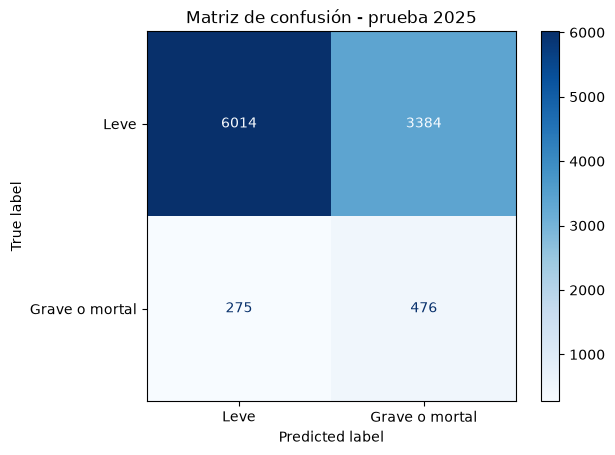

In [12]:
# GridSearchCV ya reentrenó la mejor configuración con todo el entrenamiento (refit)
modelo_final = busqueda_logistica.best_estimator_

prob_prueba = modelo_final.predict_proba(X_prueba)[:, 1]
pred_prueba = (prob_prueba >= umbral_elegido).astype(int)

print(classification_report(y_prueba, pred_prueba, digits=3,
                            target_names=["Leve", "Grave o mortal"]))
print("Alarmas:", pred_prueba.sum(),
      "| Falsas alarmas:", ((pred_prueba == 1) & (y_prueba == 0)).sum())

ConfusionMatrixDisplay.from_predictions(y_prueba, pred_prueba,
                                        display_labels=["Leve", "Grave o mortal"],
                                        cmap="Blues")
plt.title("Matriz de confusión - prueba 2025")
plt.show()

**Observaciones:**

- En 2025, el modelo detecta 476 de los 751 siniestros graves o mortales (recall 0,634), con una precisión de 0,123 y un F1 de 0,206 para esa clase.
- El recall es menor que en la validación (0,731), por lo que en 2025 no se alcanza el 70% buscado. El modelo y el umbral no se modifican después de esta evaluación: el resultado se informa tal como se obtuvo.
- La precisión de 12,3% significa que aproximadamente 1 de cada 8 alarmas corresponde a un siniestro grave. Como en 2025 el 7,4% de los siniestros fue grave, una selección al azar acertaría 1 de cada 13,5: el modelo concentra los casos graves alrededor de 1,7 veces más que el azar.
- El costo es alto: el modelo marca como posibles graves 3.860 siniestros (38% del total), de los cuales 3.384 son falsas alarmas. La exactitud (0,639) es menor que la de un modelo que siempre predice "leve" (0,926), pero ese modelo no detectaría ningún caso grave.
- En conjunto, con las variables disponibles al aviso, el modelo ordena el riesgo mejor que el azar pero con una capacidad limitada: puede servir como apoyo para priorizar, no como una clasificación confiable por sí sola.